## Recomendación: Preparación y split temporal

- Se separan train y test **por año**, sin fuga: todo lo que usa un modelo sale de los años de train

- Se construye la señal implícita entidad × proveedor y se miden los límites del problema (*cold-start*, cola larga)

### Preguntas

- **PQ3.1 - Sustitutos:** ¿se pueden identificar proveedores técnicamente afines para entidades cautivas (HHI ≥ 0.25) o procesos con postor único?

- **PQ3.2 - Cola larga:** con el 84.9% de proveedores con un solo cliente, ¿cuánto supera un híbrido (ALS + contenido con HNSW) el sesgo de popularidad del filtrado colaborativo?

- **Encuadre:** las recomendaciones son proveedores con **afinidad técnica** para un estudio de mercado previo a la convocatoria; no indican a quién se debe contratar

### Utilidades

In [1]:
NOTEBOOK = "a_preparacion_split"
%run ../funciones.ipynb
%run funciones.ipynb

/opt/conda/lib/python3.11/site-packages/nbformat/__init__.py:93: MissingIDFieldWarning: Code cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


In [2]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


---
### **1. Carga**

- `hechos`: una fila por award × proveedor × familia; se colapsa a award × proveedor sumando `monto_asignado`

- `participantes`: quién ofertó en cada proceso (base del contenido para proveedores que nunca ganaron)

In [3]:
hechos = leer(final_dir, "hechos").where(F.col("anio").isin(anios))
part   = leer(final_dir, "participantes").where(F.col("anio").isin(anios))

hp = (hechos.groupBy("ocid", "award_id", "entidad_key", "proveedor_key", "anio")
            .agg(F.sum("monto_asignado").alias("monto"))).cache()
ep = (hp.groupBy("entidad_key", "proveedor_key", "anio")
        .agg(F.count("*").alias("n_adj"), F.sum("monto").alias("monto"))).cache()
print(f"award × proveedor: {hp.count():,} | entidad × proveedor × año: {ep.count():,}")
ep.groupBy("anio").agg(F.count("*").alias("pares"), F.countDistinct("entidad_key").alias("entidades"),
                       F.countDistinct("proveedor_key").alias("proveedores")).orderBy("anio").show()

award × proveedor: 199,437 | entidad × proveedor × año: 159,162


+----+-----+---------+-----------+
|anio|pares|entidades|proveedores|
+----+-----+---------+-----------+
|2023|51181|     2619|      33828|
|2024|54785|     2741|      37081|
|2025|53196|     2804|      36835|
+----+-----+---------+-----------+



---
### **2. Winsorización del monto**

- El monto tiene cola pesada (obras de cientos de millones): sin recorte, un par dominaría la confianza de ALS

- El cuantil se calcula **solo con train** de cada split

In [4]:
q_split = {}
for nombre, sp in SPLITS.items():
    tr = ep.where(F.col("anio").isin(sp["train"])).groupBy("entidad_key", "proveedor_key").agg(F.sum("monto").alias("m"))
    q_split[nombre] = tr.where("m > 0").select(F.log1p("m").alias("lm")).approxQuantile("lm", [Q_WINSOR], .001)[0]
    print(f"{nombre}: q{int(Q_WINSOR * 100)} de log1p(monto) = {q_split[nombre]:.2f} (S/{np.expm1(q_split[nombre]):,.0f})")

ajuste: q99 de log1p(monto) = 16.70 (S/17,914,256)


final: q99 de log1p(monto) = 16.85 (S/20,731,325)


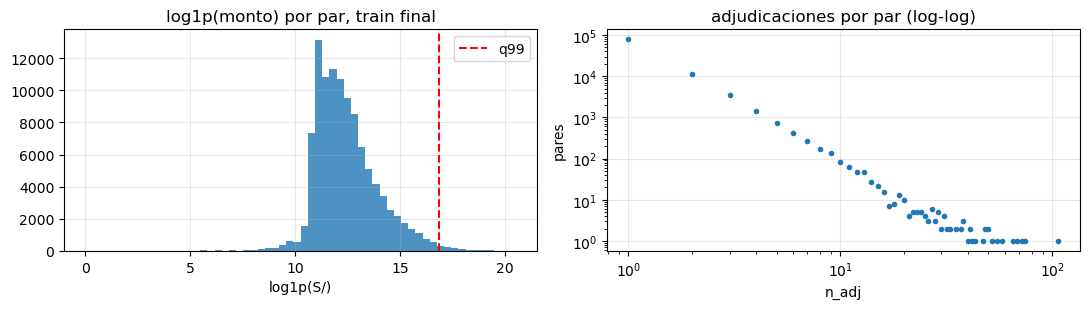

In [5]:
lm = ep.where(F.col("anio").isin(SPLITS["final"]["train"]) & (F.col("monto") > 0)).select(F.log1p("monto").alias("lm")).toPandas()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(lm.lm, bins=60, color="tab:blue", alpha=.8)
ax[0].axvline(q_split["final"], color="red", ls="--", label=f"q{int(Q_WINSOR * 100)}")
ax[0].set(title="log1p(monto) por par, train final", xlabel="log1p(S/)"); ax[0].legend()
n = ep.where(F.col("anio").isin(SPLITS["final"]["train"])).groupBy("entidad_key", "proveedor_key").agg(F.sum("n_adj").alias("n")).groupBy("n").count().toPandas().sort_values("n")
ax[1].loglog(n.n, n["count"], "o", ms=3)
ax[1].set(title="adjudicaciones por par (log-log)", xlabel="n_adj", ylabel="pares")
mostrar_fig("senal_distribucion")

---
### **3. Split temporal**

Para cada split:

- **train**: pares entidad × proveedor de los años de train, con `n_adj`, `monto`, `r_frec` (β = 0) y `r_mix` (β = 1)

- **índices enteros** (`entidad_idx`, `proveedor_idx`) ajustados **solo con train**: el orden del `StringIndexer` no ve el año de test

- **test**: pares del año de test, con `nuevo = 1` si el par no existía en train (sustituto real)

In [6]:
from pyspark.ml.feature import StringIndexer

def construir_split(nombre, sp):
    q = q_split[nombre]
    tr = (ep.where(F.col("anio").isin(sp["train"]))
            .groupBy("entidad_key", "proveedor_key").agg(F.sum("n_adj").alias("n_adj"), F.sum("monto").alias("monto"))
            .withColumn("r_frec", senal(F.col("n_adj"), F.col("monto"), q, 0))
            .withColumn("r_mix",  senal(F.col("n_adj"), F.col("monto"), q, 1)))
    for k, i in [("entidad_key", "entidad_idx"), ("proveedor_key", "proveedor_idx")]:
        tr = StringIndexer(inputCol=k, outputCol=i).fit(tr).transform(tr).withColumn(i, F.col(i).cast("int"))
    te = (ep.where(F.col("anio").isin(sp["test"]))
            .groupBy("entidad_key", "proveedor_key").agg(F.sum("n_adj").alias("n_adj"), F.sum("monto").alias("monto"))
            .join(tr.select("entidad_key", "proveedor_key").withColumn("visto", F.lit(1)), ["entidad_key", "proveedor_key"], "left")
            .withColumn("nuevo", F.col("visto").isNull().cast("int")).drop("visto"))
    return tr.cache(), te.cache()

split = {n: construir_split(n, sp) for n, sp in SPLITS.items()}
for n, (tr, te) in split.items():
    print(f"{n}: train {tr.count():,} pares | test {te.count():,} pares, {te.where('nuevo = 1').count():,} nuevos")

ajuste: train 51,181 pares | test 54,785 pares, 44,846 nuevos


final: train 96,027 pares | test 53,196 pares, 40,103 nuevos


---
### **4. Límites del problema**

#### a. Cold-start

Un modelo solo puede recomendar a quien conoce:

- **ALS** conoce a los proveedores que **ganaron** en train

- **Contenido** conoce además a los que solo **ofertaron** en train (tienen descripciones de procesos)

- Un proveedor que aparece por primera vez en test es inalcanzable para todos: fija el **techo** del recall

In [7]:
def limites(nombre, sp, tr, te):
    ent_tr = tr.select("entidad_key").distinct().withColumn("ent_train", F.lit(1))
    gano   = tr.select("proveedor_key").distinct().withColumn("gano_train", F.lit(1))
    oferto = (part.where(F.col("anio").isin(sp["train"])).select("proveedor_key").distinct()
                  .unionByName(tr.select("proveedor_key")).distinct().withColumn("oferto_train", F.lit(1)))
    t = (te.join(ent_tr, "entidad_key", "left").join(gano, "proveedor_key", "left").join(oferto, "proveedor_key", "left")
           .fillna(0, ["ent_train", "gano_train", "oferto_train"]))
    filas = []
    for sub, d in [("todos", t), ("nuevos", t.where("nuevo = 1"))]:
        r = d.agg(F.count("*").alias("pares"), F.avg("ent_train").alias("pct_entidad_conocida"),
                  F.avg("gano_train").alias("pct_alcanzable_als"), F.avg("oferto_train").alias("pct_alcanzable_contenido")).first().asDict()
        filas.append({"split": nombre, "pares_test": sub, **r})
    return filas, oferto

lim, oferentes_train = [], {}
for n, sp in SPLITS.items():
    f, oferentes_train[n] = limites(n, sp, *split[n]); lim += f
limites_df = pd.DataFrame(lim).round(3)
limites_df

,split,pares_test,pares,pct_entidad_conocida,pct_alcanzable_als,pct_alcanzable_contenido
0,ajuste,todos,54785,0.989,0.457,0.577
1,ajuste,nuevos,44846,0.986,0.337,0.484
2,final,todos,53196,0.992,0.504,0.592
3,final,nuevos,40103,0.989,0.341,0.459


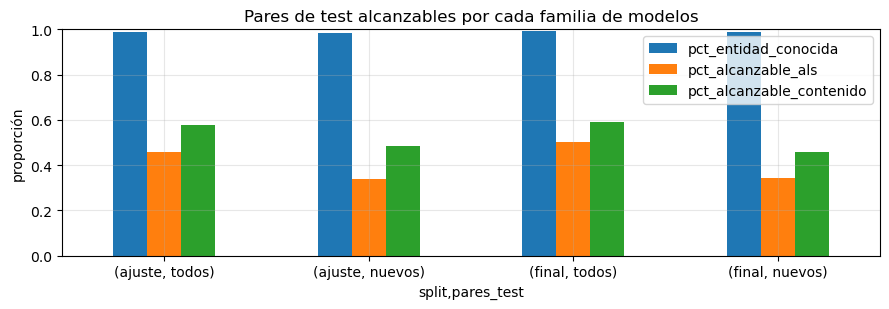

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.2))
d = limites_df.set_index(["split", "pares_test"])[["pct_entidad_conocida", "pct_alcanzable_als", "pct_alcanzable_contenido"]]
d.plot.bar(ax=ax, rot=0)
ax.set(title="Pares de test alcanzables por cada familia de modelos", ylabel="proporción", ylim=(0, 1))
mostrar_fig("cold_start")

#### b. Cola larga y popularidad

- `popularidad`: entidades clientes del proveedor en train

- `cola_larga = 1` si tiene **un solo** cliente en train

In [9]:
catalogo = {}
for n, (tr, te) in split.items():
    catalogo[n] = (oferentes_train[n].select("proveedor_key")
        .join(tr.groupBy("proveedor_key", "proveedor_idx").agg(F.countDistinct("entidad_key").alias("popularidad"),
                                                                  F.sum("n_adj").alias("n_adj_train")), "proveedor_key", "left")
        .fillna(0, ["popularidad", "n_adj_train"])
        .withColumn("gano_train", (F.col("popularidad") > 0).cast("int"))
        .withColumn("cola_larga", (F.col("popularidad") == 1).cast("int"))).cache()

cola = pd.DataFrame([{"split": n, **c.agg(F.count("*").alias("catalogo"), F.sum("gano_train").alias("ganadores_train"),
                                          F.sum("cola_larga").alias("cola_larga")).first().asDict()} for n, c in catalogo.items()])
cola["pct_cola_larga_ganadores"] = (cola.cola_larga / cola.ganadores_train).round(3)
cola

,split,catalogo,ganadores_train,cola_larga,pct_cola_larga_ganadores
0,ajuste,109323,33828,28354,0.838
1,final,192305,61145,51492,0.842


#### c. Sesgo de popularidad en test

¿Los pares nuevos de test van a proveedores populares o a la cola larga?

In [10]:
sesgo = []
for n, (tr, te) in split.items():
    t = te.join(catalogo[n].select("proveedor_key", "popularidad", "cola_larga"), "proveedor_key", "left").fillna(0, ["popularidad", "cola_larga"])
    for sub, d in [("todos", t), ("nuevos", t.where("nuevo = 1"))]:
        r = d.agg(F.avg("cola_larga").alias("pct_a_cola_larga"), F.expr("percentile_approx(popularidad, 0.5)").alias("popularidad_mediana"),
                  F.avg((F.col("popularidad") == 0).cast("int")).alias("pct_a_no_ganadores")).first().asDict()
        sesgo.append({"split": n, "pares_test": sub, **r})
sesgo = pd.DataFrame(sesgo).round(3)
sesgo

,split,pares_test,pct_a_cola_larga,popularidad_mediana,pct_a_no_ganadores
0,ajuste,todos,0.139,0,0.543
1,ajuste,nuevos,0.089,0,0.663
2,final,todos,0.139,1,0.496
3,final,nuevos,0.084,0,0.659


---
### **5. Entidades evaluables**

- Una entidad se evalúa si es conocida en train y tiene al menos un par en test

- Se guarda también el subconjunto de **cautivas** (HHI ≥ `UMBRAL_HHI` en train) para PQ3.1

In [11]:
evaluables = {}
for n, (tr, te) in split.items():
    w = Window.partitionBy("entidad_key")
    hhi = (tr.where("monto > 0").withColumn("s", F.col("monto") / F.sum("monto").over(w))
             .groupBy("entidad_key").agg(F.sum(F.col("s") ** 2).alias("hhi_train")))
    evaluables[n] = (te.select("entidad_key").distinct()
        .join(tr.select("entidad_key", "entidad_idx").distinct(), "entidad_key")
        .join(hhi, "entidad_key", "left").fillna(0, ["hhi_train"])
        .withColumn("cautiva", (F.col("hhi_train") >= UMBRAL_HHI).cast("int"))
        .join(te.groupBy("entidad_key").agg(F.count("*").alias("relevantes"), F.sum("nuevo").alias("relevantes_nuevos")), "entidad_key")).cache()

entidades_eval = pd.DataFrame([{"split": n, **e.agg(F.count("*").alias("entidades"), F.sum("cautiva").alias("cautivas"),
                                                    F.expr("percentile_approx(relevantes, 0.5)").alias("relevantes_mediana"),
                                                    F.sum((F.col("relevantes_nuevos") > 0).cast("int")).alias("con_relevantes_nuevos")).first().asDict()}
                               for n, e in evaluables.items()])
entidades_eval

,split,entidades,cautivas,relevantes_mediana,con_relevantes_nuevos
0,ajuste,2500,1323,9,2465
1,final,2672,1097,9,2609


---
### **6. Escritura de datos**

`temp/datos/<split>_<tabla>`: lo que leen `b_baseline_als`, `c_contenido_ann` y `d_hibrido_evaluacion`

| Tabla | Grano | Columnas |
|---|---|---|
| `train` | entidad × proveedor | `entidad_key`, `proveedor_key`, `entidad_idx`, `proveedor_idx`, `n_adj`, `monto`, `r_frec`, `r_mix` |
| `test` | entidad × proveedor | `entidad_key`, `proveedor_key`, `n_adj`, `monto`, `nuevo` |
| `catalogo` | proveedor | `proveedor_key`, `proveedor_idx`, `popularidad`, `gano_train`, `cola_larga` |
| `evaluables` | entidad | `entidad_key`, `entidad_idx`, `hhi_train`, `cautiva`, `relevantes`, `relevantes_nuevos` |

In [12]:
for n in SPLITS:
    tr, te = split[n]
    for nombre, df in [("train", tr), ("test", te), ("catalogo", catalogo[n]), ("evaluables", evaluables[n])]:
        df.write.mode("overwrite").parquet(str(datos_dir / f"{n}_{nombre}"))

config = leer_config()
config.update(splits=SPLITS, q_winsor=Q_WINSOR, q_log_monto=q_split, umbral_hhi=UMBRAL_HHI, ks=KS)
guardar_config(config)

#### a. Verificación

- Ningún par de train tiene año de test

- Índices enteros contiguos desde 0

- Las llaves de test y train no se pisan

In [13]:
for n, sp in SPLITS.items():
    tr = pd.read_parquet(datos_dir / f"{n}_train")
    te = pd.read_parquet(datos_dir / f"{n}_test")
    assert not tr.duplicated(["entidad_key", "proveedor_key"]).any(), n
    assert tr.entidad_idx.min() == 0 and tr.entidad_idx.max() == tr.entidad_key.nunique() - 1, n
    assert tr.proveedor_idx.min() == 0 and tr.proveedor_idx.max() == tr.proveedor_key.nunique() - 1, n
    vistos = set(zip(tr.entidad_key, tr.proveedor_key))
    assert (te.nuevo == [int(p not in vistos) for p in zip(te.entidad_key, te.proveedor_key)]).all(), n
    print(f"{n}: OK | train {len(tr):,} | test {len(te):,} ({te.nuevo.mean():.1%} nuevos)")

ajuste: OK | train 51,181 | test 54,785 (81.9% nuevos)


final: OK | train 96,027 | test 53,196 (75.4% nuevos)


### **7. Escritura de resultados**

In [14]:
escritos = guardar_tablas({"limites_cold_start": limites_df, "cola_larga": cola, "sesgo_popularidad_test": sesgo,
                           "entidades_evaluables": entidades_eval})

Escrito en 03_Recomendacion/temp/a_preparacion_split/: limites_cold_start, cola_larga, sesgo_popularidad_test, entidades_evaluables


#### a. Verificación

In [15]:
verificar_salidas(escritos)

OK: 4 tablas (parquet + json) | 2 figuras: cold_start, senal_distribucion


---
### **8. Cerrar sesión**

In [16]:
spark.stop()